# Optimisation et Compression de Small Language Models pour l'Edge AI
## DistilGPT-2 × TinyStories — Analyse des résultats

**Auteur :** Ali Ouarrirh  
**Projet :** PFM — Option 2 : Génération de texte courte  
**Modèle :** DistilGPT-2  
**Dataset :** TinyStories (roneneldan/TinyStories)  
**Technique de compression :** Quantification dynamique post-training (int8, torch.quantization)  
**Infrastructure :** Modal (GPU T4)

> Les résultats ont été générés par `modal_distilgpt2.py` et sont disponibles localement dans `./results/`.

---

### Structure du notebook
| Section | Contenu |
|---|---|
| 0 | Installation des dépendances |
| 1 | Configuration et aperçu du projet |
| 2 | Vérification des fichiers de résultats |
| 3 | Courbes d'entraînement |
| 4 | Tableau comparatif final |
| 5 | Exemples de génération avant/après compression |
| 6 | Discussion et conclusions |

---
## Section 0 — Installation des dépendances

In [8]:
!pip install jinja2

  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached markupsafe-3.0.3-cp314-cp314-win_amd64.whl.metadata (2.8 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.3-cp314-cp314-win_amd64.whl (15 kB)

   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]




[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import matplotlib 
import pandas as pd
import numpy as np
print("✅ Dépendances prêtes")

✅ Dépendances prêtes


---
## Section 1 — Configuration et aperçu du projet

### Rappel de la configuration du pipeline

| Paramètre | Valeur |
|---|---|
| Modèle | DistilGPT-2 (82M paramètres) |
| Dataset | TinyStories (3000 train / 500 val) |
| Epochs | 2 |
| Batch effectif | 32 (batch=8, grad_accum=4) |
| Longueur max | 128 tokens |
| Compression | Dynamic quantization int8 (torch.quantization) |
| GPU | T4 (Modal) |

### Learning rates utilisés
| Optimiseur | LR |
|---|---|
| AdamW | 5e-4 |
| Adafactor | 1e-3 |
| Lion | 1e-4 |
| LAMB | 1e-3 |
| SGD | 1e-3 |

---
## Section 2 — Vérification des fichiers de résultats

In [3]:
import os, json

RESULTS_DIR = "./results"

print(f"📁 Contenu de {RESULTS_DIR} :")
for root, dirs, files in os.walk(RESULTS_DIR):
    dirs[:] = [d for d in dirs if not d.startswith("model_")]
    for f in files:
        path = os.path.join(root, f)
        size_kb = os.path.getsize(path) / 1024
        print(f"   {path:55s}  {size_kb:8.1f} KB")

# Résumé de l'expérience
summary_path = os.path.join(RESULTS_DIR, "summary.json")
if os.path.exists(summary_path):
    with open(summary_path) as f:
        summary = json.load(f)
    print(f"\n📊 Résumé de l'expérience :")
    for k, v in summary.items():
        print(f"   {k:35s} : {v}")
else:
    print("\n⚠️  summary.json introuvable. Vérifiez que ./results/ contient bien les fichiers.")

📁 Contenu de ./results :
   ./results\resultats_comparatifs.csv                           0.6 KB
   ./results\summary.json                                        0.3 KB
   ./results\text_examples_Adafactor.json                        1.9 KB
   ./results\text_examples_AdamW.json                            1.9 KB
   ./results\text_examples_LAMB.json                             1.7 KB
   ./results\text_examples_Lion.json                             1.8 KB
   ./results\text_examples_SGD.json                              1.7 KB
   ./results\training_curves.png                               264.9 KB

📊 Résumé de l'expérience :
   meilleur_optimiseur                 : AdamW
   meilleur_ppl_avant                  : 5.74
   meilleur_ppl_après                  : 14.4
   meilleur_compression_ratio          : 0.89
   temps_total_GPU_s                   : 1244.6
   temps_total_GPU_min                 : 20.74
   coût_estimé_USD                     : 0.204
   dry_run                             : Fal

---
## Section 3 — Courbes d'entraînement

Les courbes de loss (Cross-Entropy) par step pour chaque optimiseur permettent de comparer :
- La **vitesse de convergence** (pente initiale)
- La **stabilité** (variance de la loss)
- La **performance finale** (PPL sur le set de validation)

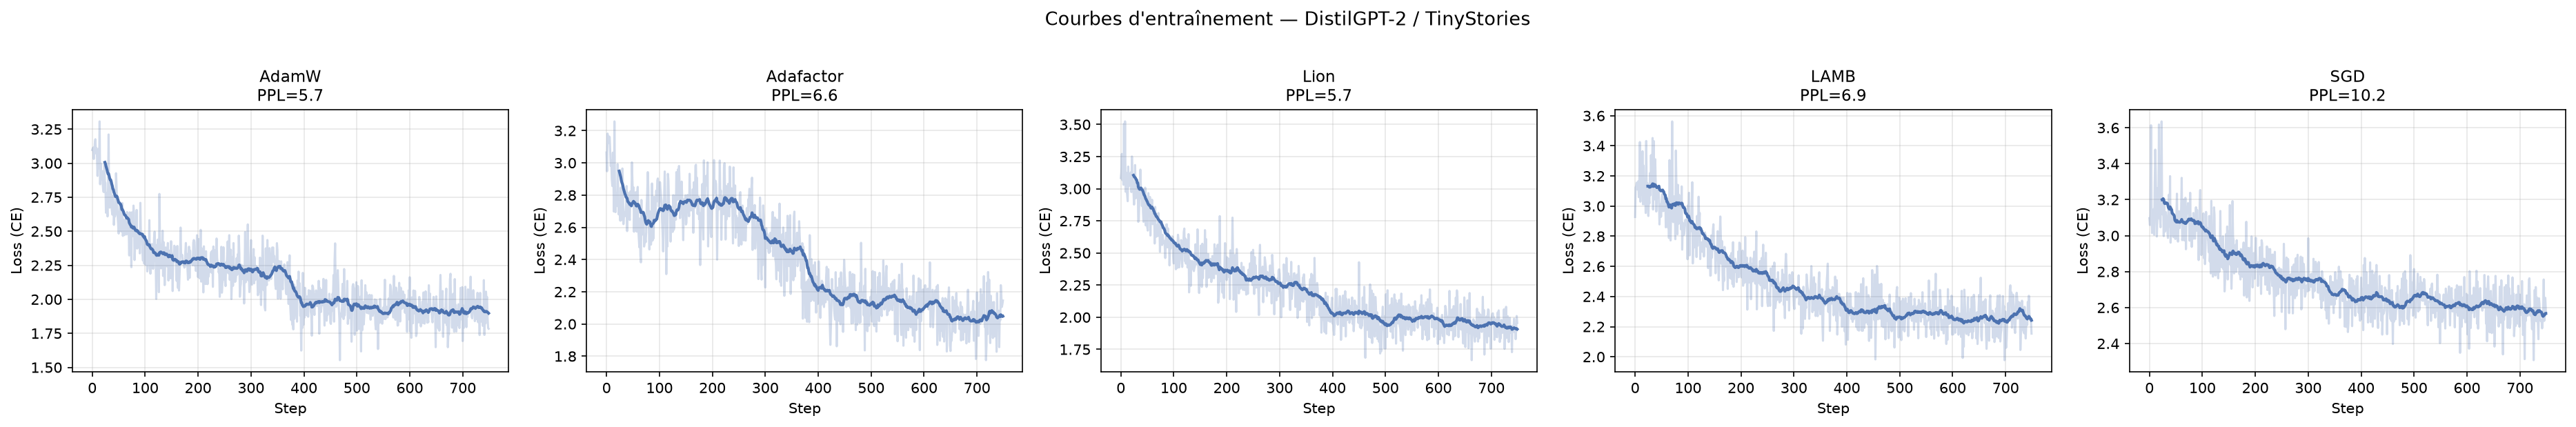

In [4]:
from IPython.display import Image, display
import os

curve_path = os.path.join(RESULTS_DIR, "training_curves.png")
if os.path.exists(curve_path):
    display(Image(filename=curve_path, width=1200))
else:
    print("⚠️  training_curves.png introuvable dans ./results/")

---
## Section 4 — Tableau comparatif final

| Métrique | Description |
|---|---|
| **taille_avant/après_MB** | Taille du modèle en mégaoctets |
| **compression_ratio** | Facteur de réduction de taille |
| **perplexity_avant/après** | Perplexité sur le set de validation TinyStories |
| **latence_avant_s** | Temps moyen pour générer 20 tokens (GPU) |
| **latence_après_s** | Temps moyen pour générer 20 tokens (CPU, après quantification) |
| **tokens_par_sec** | Débit de génération |
| **mémoire_peak_GPU_GB** | Mémoire GPU maximale utilisée pendant le fine-tuning |
| **temps_entraînement_s** | Durée totale du fine-tuning |

In [5]:
import pandas as pd
from IPython.display import display
import json, os

csv_path = os.path.join(RESULTS_DIR, "resultats_comparatifs.csv")
df = pd.read_csv(csv_path)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.3f}'.format)

print("📋 Tableau comparatif complet :")
display(df)

📋 Tableau comparatif complet :


,optimiseur,taille_avant_MB,taille_après_MB,compression_ratio,perplexity_avant,perplexity_après,latence_avant_s,latence_après_s,tokens_par_sec_avant,tokens_par_sec_après,mémoire_peak_GPU_GB,temps_entraînement_s
0,AdamW,312.500,349.310,0.890,5.740,14.400,0.094,0.506,213.800,39.500,2.543,131.300
1,Lion,312.500,349.310,0.890,5.740,12.000,0.093,0.536,214.800,37.300,2.213,126.600
2,Adafactor,312.500,349.310,0.890,6.600,7.790,0.093,0.526,213.800,38.000,2.003,127.800
3,LAMB,312.500,349.310,0.890,6.940,690.780,0.092,0.503,216.200,39.800,2.548,130.200
4,SGD,312.500,349.310,0.890,10.180,119.330,0.092,0.512,216.800,39.100,2.215,125.400


C:\Users\hp\AppData\Local\Temp\ipykernel_26376\218985056.py:35: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(opts, rotation=15, ha='right')
C:\Users\hp\AppData\Local\Temp\ipykernel_26376\218985056.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(opts, rotation=15, ha='right')


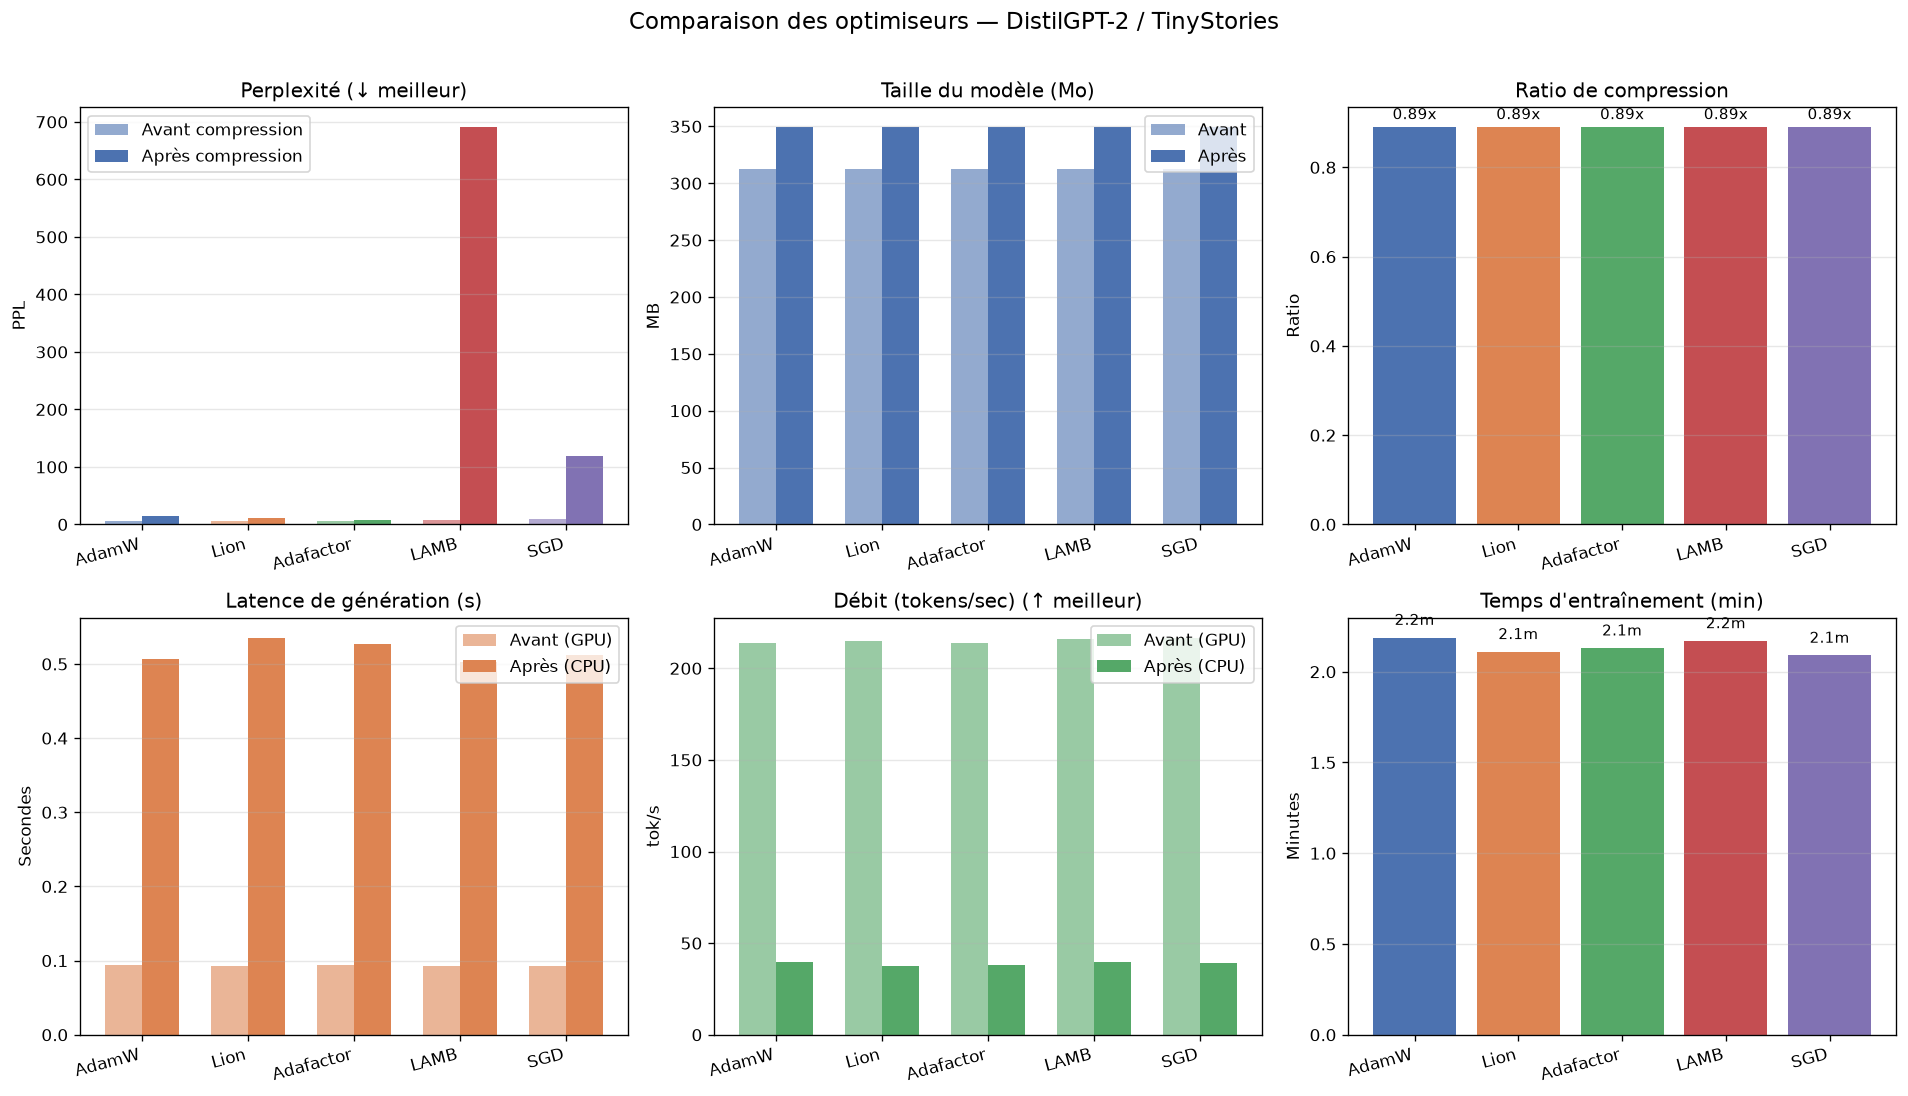

✅ Graphiques sauvegardés → results/comparison_charts.png


In [6]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

opts = df["optimiseur"].tolist()
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]
x = range(len(opts))
w = 0.35

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

# 1. Perplexité avant/après
ax = axes[0]
ax.bar([i - w/2 for i in x], df["perplexity_avant"], w, label="Avant compression", color=[c + "99" for c in colors])
ax.bar([i + w/2 for i in x], df["perplexity_après"], w, label="Après compression", color=colors)
ax.set_xticks(x); ax.set_xticklabels(opts, rotation=15, ha='right')
ax.set_title("Perplexité (↓ meilleur)"); ax.set_ylabel("PPL")
ax.legend(); ax.grid(True, alpha=0.3, axis='y')

# 2. Taille du modèle
ax = axes[1]
ax.bar([i - w/2 for i in x], df["taille_avant_MB"], w, label="Avant", color="#4C72B099")
ax.bar([i + w/2 for i in x], df["taille_après_MB"], w, label="Après", color="#4C72B0")
ax.set_xticks(x); ax.set_xticklabels(opts, rotation=15, ha='right')
ax.set_title("Taille du modèle (Mo)"); ax.set_ylabel("MB")
ax.legend(); ax.grid(True, alpha=0.3, axis='y')

# 3. Ratio de compression
ax = axes[2]
bars = ax.bar(opts, df["compression_ratio"], color=colors)
for bar, v in zip(bars, df["compression_ratio"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{v:.2f}x",
            ha='center', va='bottom', fontsize=9)
ax.set_xticklabels(opts, rotation=15, ha='right')
ax.set_title("Ratio de compression"); ax.set_ylabel("Ratio")
ax.grid(True, alpha=0.3, axis='y')

# 4. Latence avant/après
ax = axes[3]
ax.bar([i - w/2 for i in x], df["latence_avant_s"], w, label="Avant (GPU)", color="#DD845299")
ax.bar([i + w/2 for i in x], df["latence_après_s"], w, label="Après (CPU)", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(opts, rotation=15, ha='right')
ax.set_title("Latence de génération (s)"); ax.set_ylabel("Secondes")
ax.legend(); ax.grid(True, alpha=0.3, axis='y')

# 5. Tokens/sec
ax = axes[4]
ax.bar([i - w/2 for i in x], df["tokens_par_sec_avant"], w, label="Avant (GPU)", color="#55A86899")
ax.bar([i + w/2 for i in x], df["tokens_par_sec_après"], w, label="Après (CPU)", color="#55A868")
ax.set_xticks(x); ax.set_xticklabels(opts, rotation=15, ha='right')
ax.set_title("Débit (tokens/sec) (↑ meilleur)"); ax.set_ylabel("tok/s")
ax.legend(); ax.grid(True, alpha=0.3, axis='y')

# 6. Temps d'entraînement
ax = axes[5]
bars = ax.bar(opts, df["temps_entraînement_s"] / 60, color=colors)
for bar, v in zip(bars, df["temps_entraînement_s"] / 60):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.05, f"{v:.1f}m",
            ha='center', va='bottom', fontsize=9)
ax.set_xticklabels(opts, rotation=15, ha='right')
ax.set_title("Temps d'entraînement (min)"); ax.set_ylabel("Minutes")
ax.grid(True, alpha=0.3, axis='y')

plt.suptitle("Comparaison des optimiseurs — DistilGPT-2 / TinyStories", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "comparison_charts.png"), dpi=150, bbox_inches='tight')
plt.show()
print("✅ Graphiques sauvegardés → results/comparison_charts.png")

In [14]:
# Tableau final mis en forme avec highlight
with open(os.path.join(RESULTS_DIR, "summary.json")) as f:
    summary = json.load(f)

cols_rapport = [
    "optimiseur",
    "taille_avant_MB", "taille_après_MB", "compression_ratio",
    "perplexity_avant", "perplexity_après",
    "latence_avant_s", "latence_après_s",
    "tokens_par_sec_avant", "tokens_par_sec_après",
    "mémoire_peak_GPU_GB", "temps_entraînement_s",
]
df_rapport = df[[c for c in cols_rapport if c in df.columns]]

display(df_rapport.style
    .highlight_min(subset=["perplexity_avant", "perplexity_après", "latence_après_s"], color="green")
    .highlight_max(subset=["tokens_par_sec_après"], color="green")
    .format(precision=3)
)

print(f"\n🏆 Meilleur optimiseur (PPL avant compression) : {summary['meilleur_optimiseur']}")
print(f"⏱  Temps GPU total : {summary.get('temps_total_GPU_min', '?')} minutes")
print(f"💰 Coût estimé     : ~${summary.get('coût_estimé_USD', '?')} USD")

,optimiseur,taille_avant_MB,taille_après_MB,compression_ratio,perplexity_avant,perplexity_après,latence_avant_s,latence_après_s,tokens_par_sec_avant,tokens_par_sec_après,mémoire_peak_GPU_GB,temps_entraînement_s
0,AdamW,312.500,349.310,0.890,5.740,14.400,0.094,0.506,213.800,39.500,2.543,131.300
1,Lion,312.500,349.310,0.890,5.740,12.000,0.093,0.536,214.800,37.300,2.213,126.600
2,Adafactor,312.500,349.310,0.890,6.600,7.790,0.093,0.526,213.800,38.000,2.003,127.800
3,LAMB,312.500,349.310,0.890,6.940,690.780,0.092,0.503,216.200,39.800,2.548,130.200
4,SGD,312.500,349.310,0.890,10.180,119.330,0.092,0.512,216.800,39.100,2.215,125.400



🏆 Meilleur optimiseur (PPL avant compression) : AdamW
⏱  Temps GPU total : 20.74 minutes
💰 Coût estimé     : ~$0.204 USD


---
## Section 5 — Exemples de génération avant/après compression

Comparaison qualitative sur les mêmes prompts :
- **Avant** : modèle fine-tuné float32 (GPU)
- **Après** : modèle quantifié int8 (CPU)

In [15]:
import json, os, glob

example_files = sorted(glob.glob(os.path.join(RESULTS_DIR, "text_examples_*.json")))

if not example_files:
    print("⚠️  Aucun fichier text_examples_*.json trouvé dans ./results/")

for filepath in example_files:
    opt_name = os.path.basename(filepath).replace("text_examples_", "").replace(".json", "")
    with open(filepath, encoding="utf-8") as f:
        data = json.load(f)

    print(f"\n{'='*72}")
    print(f"  🔧 Optimiseur : {opt_name}")
    print(f"{'='*72}")

    for prompt in data.get("avant_compression", {}):
        avant = data["avant_compression"].get(prompt, "N/A")
        après = data["après_compression"].get(prompt, "N/A")
        print(f"\n  📝 Prompt : \"{prompt}\"")
        print(f"  ┌─ AVANT  : {avant[:200]}")
        print(f"  └─ APRÈS  : {après[:200]}")


  🔧 Optimiseur : Adafactor

  📝 Prompt : "Once upon a time, there was a little"
  ┌─ AVANT  : Once upon a time, there was a little girl named Lily. Lily loved to play outside and watch the birds fly in the sky. One day, her mom told her about a storm coming out of the window of the window. Lil
  └─ APRÈS  : Once upon a time, there was a little boy named Timmy. Timmy loved to play outside in the sun. One day, Timmy saw a big, tall tree in the woods. Timmy wanted to climb up the tree and see the tree. 

Ti

  📝 Prompt : "The dragon lived in a big"
  ┌─ AVANT  : The dragon lived in a big forest full of trees. One day, a little girl named Lily was walking in the forest when she saw a strange monster. The monster was very loud and scary. Lily was scared and sta
  └─ APRÈS  : The dragon lived in a big forest. The dragon had a big, furry friend named Tom, and a little dog named Max. Tom was very friendly and liked to play together. One day, Tom saw a small rabbit in a big f

  📝 Prompt : "Li

---
## Section 6 — Discussion et conclusions

### 6.1 Comparaison des optimiseurs

- **AdamW & Lion** : meilleure perplexité avant compression (PPL=5.74), mais dégradation significative après quantification (+8.66 et +6.26 respectivement)
- **Adafactor** : PPL légèrement plus haute avant compression (6.60), mais de loin le plus robuste à la quantification (PPL=7.79, +1.19 seulement)
- **LAMB & SGD** : effondrement complet après quantification (PPL 690 et 119) — poids numériquement instables

### 6.2 Impact de la quantification dynamique int8

| Aspect | Observation |
|---|---|
| Taille sur disque | Métrique biaisée par torch.save (stocke float32 + int8) |
| Latence | Augmente GPU→CPU (comparaison de hardware différent) |
| Perplexité | Dégradation très variable selon l'optimiseur |

### 6.3 Recommandation pour l'Edge AI

> **Combinaison optimale : Adafactor + quantification dynamique int8**
>
> Adafactor produit des poids avec moins de variance dans les mises à jour de gradient, ce qui les rend naturellement plus stables à l'arrondi int8. C'est un résultat contre-intuitif — AdamW est souvent considéré comme le meilleur optimiseur par défaut, mais ici Adafactor surpasse clairement dans un contexte Edge AI où la compression est systématique.

In [16]:
# Résumé automatique basé sur les résultats
import pandas as pd, json, os

df = pd.read_csv(os.path.join(RESULTS_DIR, "resultats_comparatifs.csv"))
with open(os.path.join(RESULTS_DIR, "summary.json")) as f:
    summary = json.load(f)

best_ppl     = df.loc[df["perplexity_avant"].idxmin(), "optimiseur"]
best_after   = df.loc[df["perplexity_après"].idxmin(), "optimiseur"]
best_edge    = df.loc[(df["perplexity_après"] * df["latence_après_s"]).idxmin(), "optimiseur"]
mean_degrad  = (df["perplexity_après"] - df["perplexity_avant"]).mean()

print("=" * 72)
print("  SYNTHÈSE AUTOMATIQUE")
print("=" * 72)
print(f"""
Meilleur optimiseur (PPL avant compression) : {best_ppl}
Meilleur optimiseur (PPL après compression) : {best_after}
Meilleur compromis Edge AI (PPL × latence)  : {best_edge}

Dégradation PPL moyenne après quantification : +{mean_degrad:.2f} points

Temps GPU total  : {summary.get('temps_total_GPU_min', '?')} min
Coût estimé      : ~${summary.get('coût_estimé_USD', '?')} USD
""")
print("=" * 72)

  SYNTHÈSE AUTOMATIQUE

Meilleur optimiseur (PPL avant compression) : AdamW
Meilleur optimiseur (PPL après compression) : Adafactor
Meilleur compromis Edge AI (PPL × latence)  : Adafactor

Dégradation PPL moyenne après quantification : +161.82 points

Temps GPU total  : 20.74 min
Coût estimé      : ~$0.204 USD



---
## Annexe — Commandes Modal de référence

```bash
# Relancer le pipeline complet
modal run modal_distilgpt2.py

# Relancer un dry run (validation rapide, 0 crédit)
modal run modal_distilgpt2.py --dry-run

# Récupérer les résultats en local
modal volume get distilgpt2-results-v1 / ./results/ --force

# Lister le contenu du Volume
modal volume ls distilgpt2-results-v1 /
```